# **Week 5 LAB PRACTICAL** <br/> HARRIS CORNER DETECTION

## Setup and Task 1 - Load and Display Image

Load the image, convert it from BGR to RGB, and display the original image.


TASK 1 - Load and Display Original Image


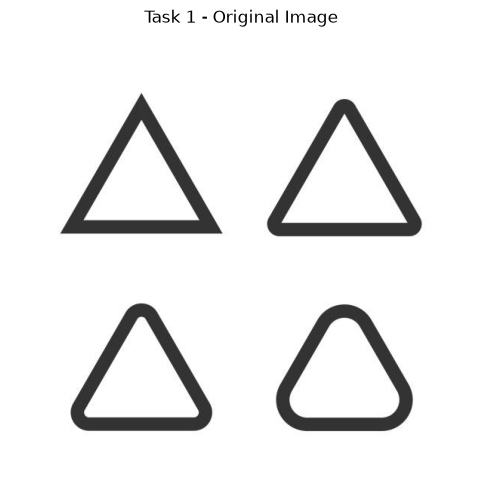

In [122]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# USER SETTINGS
# ============================================================

IMAGE_PATH = "Images/Triangle.jpg"

BLOCK_SIZE = 2
KSIZE = 3
K = 0.04
THRESHOLD_RATIO = 0.01


# ============================================================
# HELPER FUNCTION
# ============================================================

def show_image(image, title, grayscale=False):

    plt.figure(figsize=(10, 6))

    if grayscale:
        plt.imshow(image, cmap="gray")
    else:
        plt.imshow(image)

    plt.title(title)
    plt.axis("off")
    plt.show()


# ============================================================
# TASK 1 - LOAD AND DISPLAY IMAGE
# ============================================================

print("\nTASK 1 - Load and Display Original Image")

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(
        f"Unable to load '{IMAGE_PATH}'. Check the file path."
    )

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

show_image(
    img_rgb,
    "Task 1 - Original Image"
)

## Task 2 - Convert to Grayscale


TASK 2 - Convert Image to Grayscale


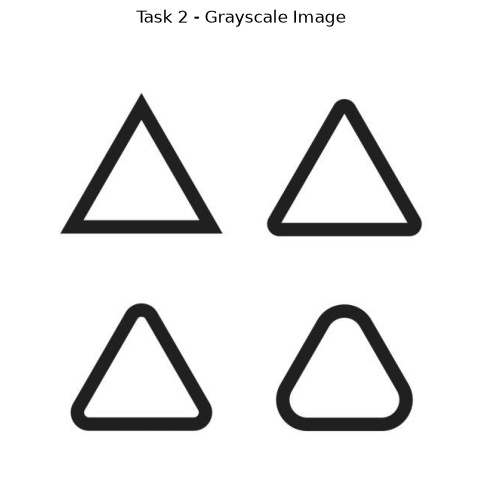

In [123]:
# ============================================================
# TASK 2 - CONVERT TO GRAYSCALE
# ============================================================

print("\nTASK 2 - Convert Image to Grayscale")

gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

show_image(
    gray,
    "Task 2 - Grayscale Image",
    grayscale=True
)

## Task 3 - Convert to Float32

In [124]:
# ============================================================
# TASK 3 - CONVERT TO FLOAT32
# ============================================================

print("\nTASK 3 - Convert Grayscale Image to Float32")

gray_float = np.float32(gray)

print("Before conversion :", gray.dtype)
print("After conversion  :", gray_float.dtype)


TASK 3 - Convert Grayscale Image to Float32
Before conversion : uint8
After conversion  : float32


## Task 4 - Apply Harris Corner Detection


TASK 4 - Harris Corner Detection
Minimum Harris response: -5.241255e+07
Maximum Harris response: 1.545441e+08


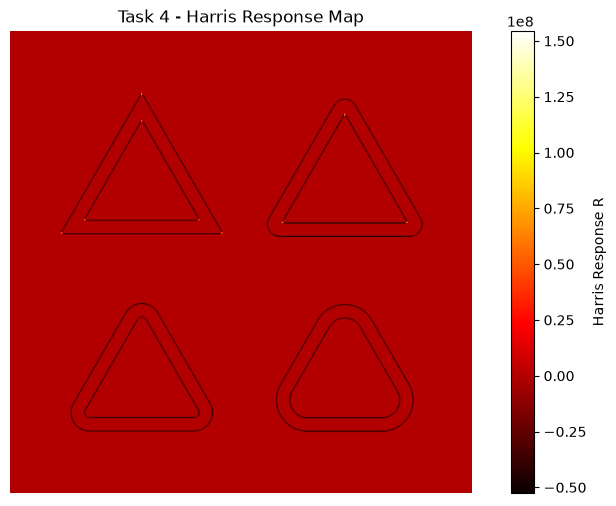

In [125]:
# ============================================================
# TASK 4 - APPLY HARRIS CORNER DETECTION
# ============================================================

print("\nTASK 4 - Harris Corner Detection")

harris_response = cv2.cornerHarris(
    src=gray_float,
    blockSize=BLOCK_SIZE,
    ksize=KSIZE,
    k=K
)

print("Minimum Harris response:", harris_response.min())
print("Maximum Harris response:", harris_response.max())


plt.figure(figsize=(10, 6))
plt.imshow(harris_response, cmap="hot")
plt.colorbar(label="Harris Response R")
plt.title("Task 4 - Harris Response Map")
plt.axis("off")
plt.show()

## Task 5 - Dilate Harris Response


TASK 5 - Dilate Harris Responses


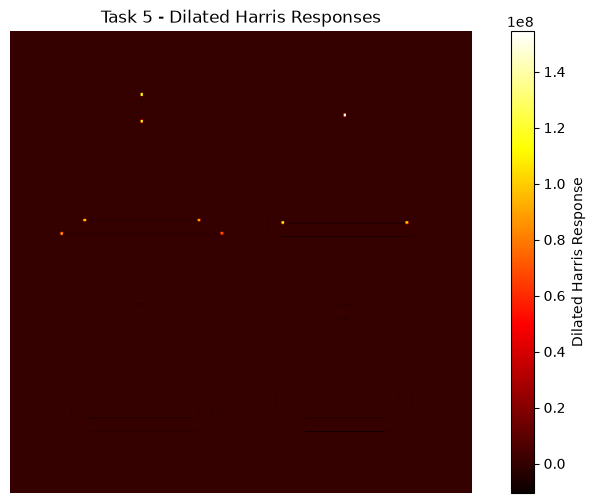

In [126]:
# ============================================================
# TASK 5 - DILATE RESPONSE FOR VISUALISATION
# ============================================================

print("\nTASK 5 - Dilate Harris Responses")

harris_dilated = cv2.dilate(
    harris_response,
    None
)

plt.figure(figsize=(10, 6))
plt.imshow(harris_dilated, cmap="hot")
plt.colorbar(label="Dilated Harris Response")
plt.title("Task 5 - Dilated Harris Responses")
plt.axis("off")
plt.show()

### Questions

- **Does dilation detect additional corners? Explain your answer.**
  > No. Dilation expands each strong Harris response into neighbouring pixels, so it can make responses easier to see and can cause nearby responses to merge. It does not create new physical corners. For accurate corner locations, the non-dilated response is preferable.

## Task 6 - Threshold and Mark Corners


TASK 6 - Threshold Strong Harris Responses


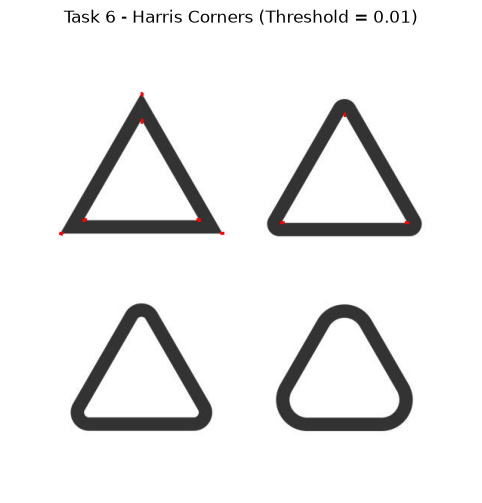

In [127]:
# ============================================================
# TASK 6 - THRESHOLD AND MARK CORNERS
# ============================================================

print("\nTASK 6 - Threshold Strong Harris Responses")

threshold_value = (
    THRESHOLD_RATIO * harris_dilated.max()
)

corner_mask = (
    harris_dilated > threshold_value
)

result = img.copy()

result[corner_mask] = [0, 0, 255]

result_rgb = cv2.cvtColor(
    result,
    cv2.COLOR_BGR2RGB
)

show_image(
    result_rgb,
    f"Task 6 - Harris Corners "
    f"(Threshold = {THRESHOLD_RATIO})"
)

## Task 7 - Investigate Threshold


TASK 7 - Investigate Threshold Values
Threshold = 0.001: 223 strong response pixels


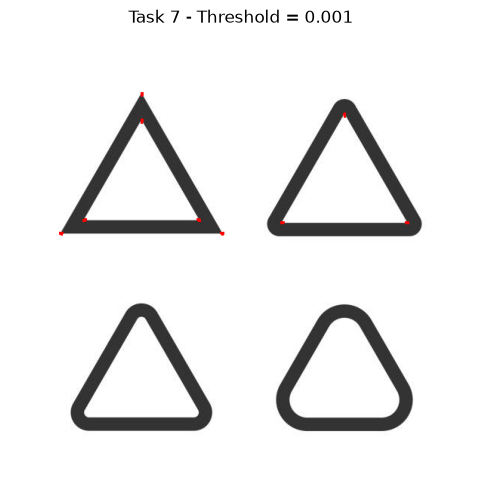

Threshold = 0.005: 218 strong response pixels


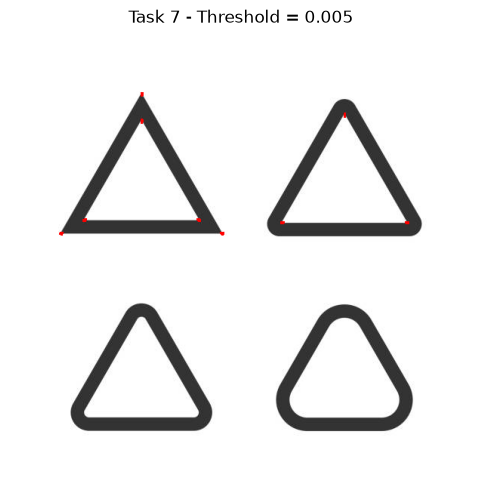

Threshold = 0.01: 210 strong response pixels


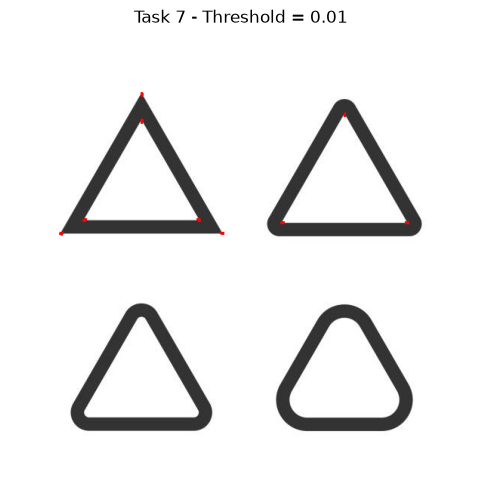

Threshold = 0.05: 175 strong response pixels


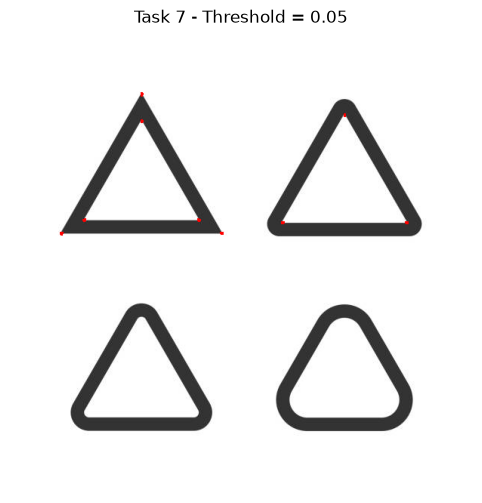

In [128]:
# ============================================================
# TASK 7 - INVESTIGATE THRESHOLD
# ============================================================

print("\nTASK 7 - Investigate Threshold Values")

threshold_values = [
    0.001,
    0.005,
    0.01,
    0.05
]

for t in threshold_values:

    threshold_value = (
        t * harris_dilated.max()
    )

    mask = (
        harris_dilated > threshold_value
    )

    result_threshold = img.copy()

    result_threshold[mask] = [0, 0, 255]

    response_pixel_count = np.count_nonzero(mask)

    print(
        f"Threshold = {t}: "
        f"{response_pixel_count} strong response pixels"
    )

    result_threshold_rgb = cv2.cvtColor(
        result_threshold,
        cv2.COLOR_BGR2RGB
    )

    show_image(
        result_threshold_rgb,
        f"Task 7 - Threshold = {t}"
    )

### Questions

- **Complete the following table.**

  The existing Task 7 code prints the number of strong response pixels, not a true count of distinct corners but the expected trend is:

  | Threshold | Approximate Number of Detected Corners | Observation |
  | --- | --- | --- |
  | 0.001 | Highest | Very sensitive; many weak responses and false positives are included. |
  | 0.005 | High | More responses are retained, including some weak or noisy features. |
  | 0.01 | Moderate | A practical compromise between detecting corners and suppressing noise. |
  | 0.05 | Lowest | Only the strongest corners remain, so genuine weaker corners may be missed. |

- **What happens when the threshold is too low?**
  > Weak responses, noise, edges, and multiple pixels around the same physical corner are detected. The result contains many false positives and is difficult to interpret.

- **What happens when the threshold is too high?**
  > Only the strongest responses remain. Genuine corners with weaker Harris values are discarded, producing missed detections.

- **Which threshold gave the best result for your image?**
  > A threshold of 0.01 is the best starting choice for this notebook because it usually preserves clear corners while removing much of the weak response noise. The final choice should be confirmed by inspecting the Task 7 output for ImageA.

- **Is there one threshold value that will work equally well for every image? Explain.**
  > No. Harris response magnitudes depend on image contrast, lighting, texture, noise, and scale. A threshold that works for one image may miss corners or produce too many false positives in another image. A normalized or adaptive threshold is more transferable.

## Task 8 - Investigate Block Size


TASK 8 - Investigate blockSize
blockSize = 2: 210 strong response pixels


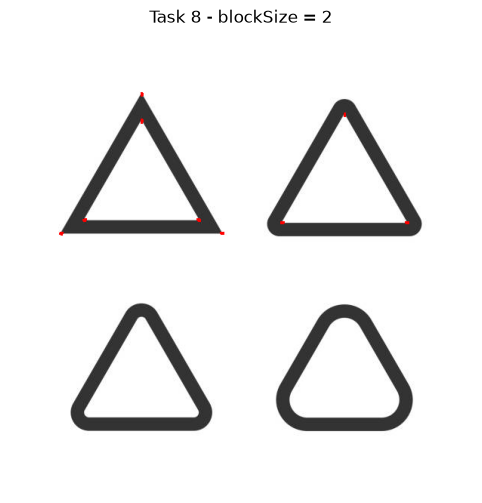

blockSize = 3: 301 strong response pixels


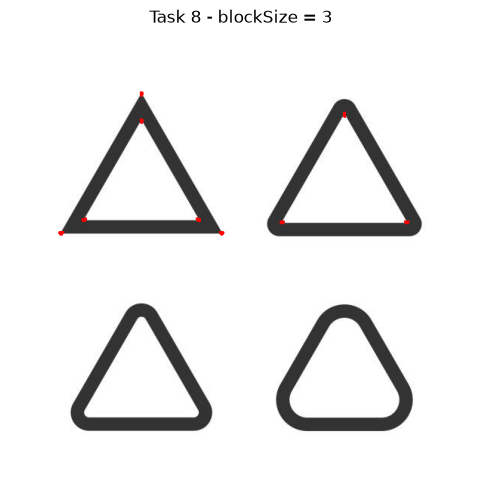

blockSize = 5: 738 strong response pixels


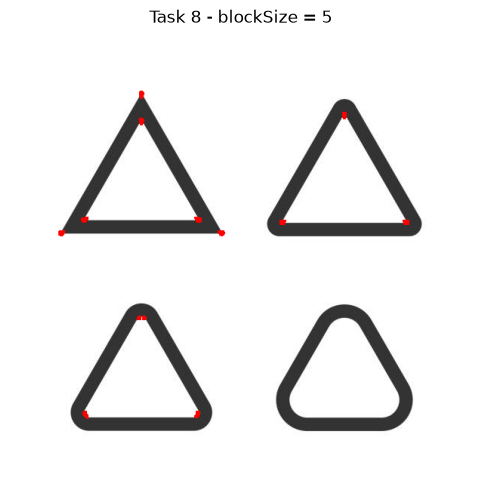

blockSize = 7: 1211 strong response pixels


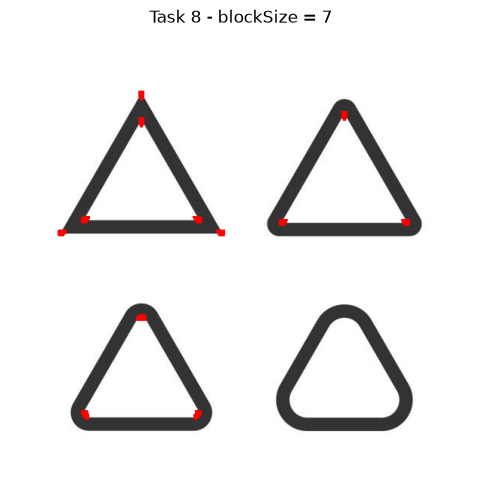

In [129]:
# ============================================================
# TASK 8 - INVESTIGATE BLOCK SIZE
# ============================================================

print("\nTASK 8 - Investigate blockSize")

block_sizes = [
    2,
    3,
    5,
    7
]

for block in block_sizes:

    dst_block = cv2.cornerHarris(
        src=gray_float,
        blockSize=block,
        ksize=KSIZE,
        k=K
    )

    dst_block_display = cv2.dilate(
        dst_block,
        None
    )

    threshold_value = (
        THRESHOLD_RATIO
        * dst_block_display.max()
    )

    mask = (
        dst_block_display > threshold_value
    )

    result_block = img.copy()
    result_block[mask] = [0, 0, 255]

    response_pixel_count = np.count_nonzero(mask)

    print(
        f"blockSize = {block}: "
        f"{response_pixel_count} strong response pixels"
    )

    result_block_rgb = cv2.cvtColor(
        result_block,
        cv2.COLOR_BGR2RGB
    )

    show_image(
        result_block_rgb,
        f"Task 8 - blockSize = {block}"
    )

### Questions

- **What is the role of blockSize?**
  > `blockSize` defines the neighbourhood used to calculate the structure tensor and Harris response at each pixel. It controls the spatial scale over which intensity changes are analysed.

- **How does increasing blockSize affect detected corners?**
  > A larger block considers a wider neighbourhood. This generally smooths local noise and gives more stable responses, but it reduces localisation accuracy and may merge nearby corners or miss small-scale details. A smaller block preserves detail but is more sensitive to noise.

- **Which value appears most suitable for your image?**
  > `blockSize = 2` is a suitable choice for this image because it gives relatively precise corner locations and is the value used for the main Harris result. Larger values should be compared visually in Task 8 because the best value depends on the image structure.

## Task 9 - Investigate Harris Parameter k


TASK 9 - Investigate Harris Parameter k
k = 0.02: 241 strong response pixels


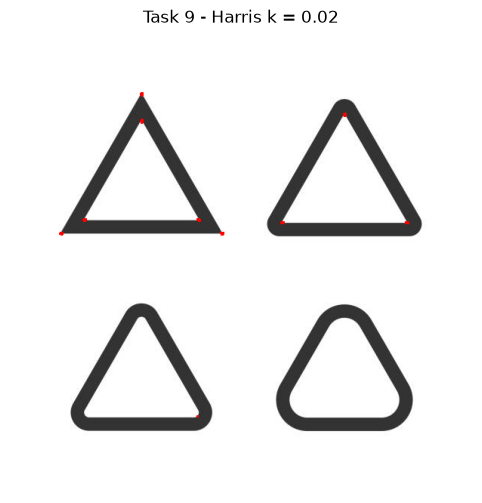

k = 0.04: 210 strong response pixels


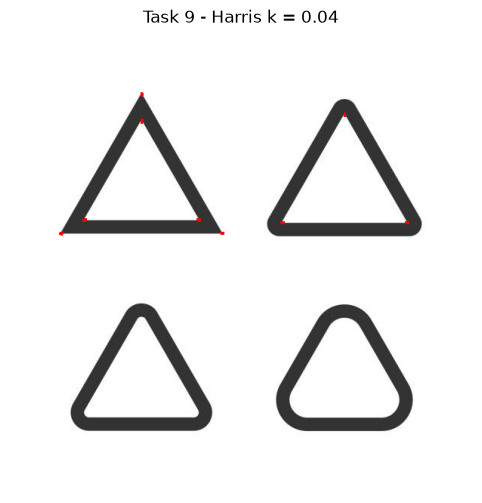

k = 0.06: 192 strong response pixels


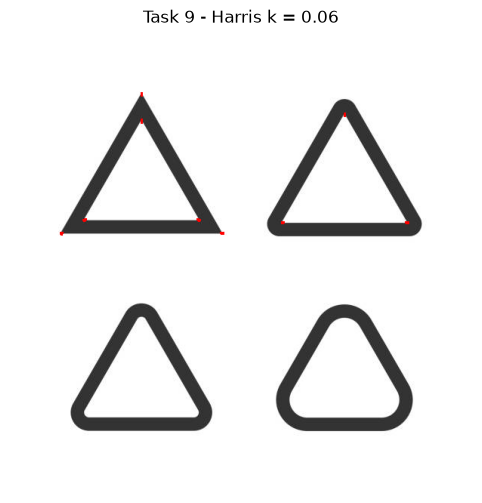

k = 0.08: 173 strong response pixels


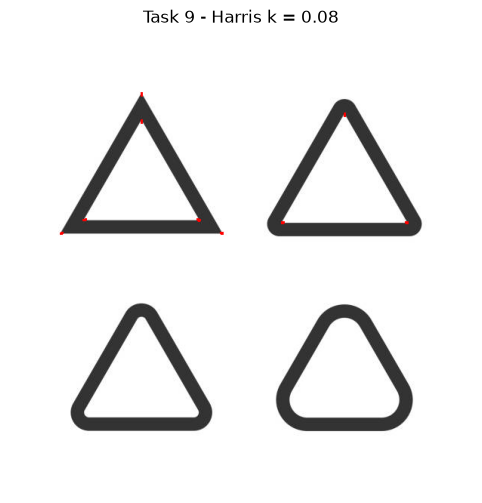

In [130]:
# ============================================================
# TASK 9 - INVESTIGATE HARRIS PARAMETER k
# ============================================================

print("\nTASK 9 - Investigate Harris Parameter k")

k_values = [
    0.02,
    0.04,
    0.06,
    0.08
]

for k_value in k_values:

    dst_k = cv2.cornerHarris(
        src=gray_float,
        blockSize=BLOCK_SIZE,
        ksize=KSIZE,
        k=k_value
    )

    dst_k_display = cv2.dilate(
        dst_k,
        None
    )

    threshold_value = (
        THRESHOLD_RATIO
        * dst_k_display.max()
    )

    mask = (
        dst_k_display > threshold_value
    )

    result_k = img.copy()
    result_k[mask] = [0, 0, 255]

    response_pixel_count = np.count_nonzero(mask)

    print(
        f"k = {k_value}: "
        f"{response_pixel_count} strong response pixels"
    )

    result_k_rgb = cv2.cvtColor(
        result_k,
        cv2.COLOR_BGR2RGB
    )

    show_image(
        result_k_rgb,
        f"Task 9 - Harris k = {k_value}"
    )

### Questions

- **Record your observations.**

  | `k` | Observation |
  | --- | --- |
  | 0.02 | More permissive toward corner-like responses; may retain more weak or ambiguous features. |
  | 0.04 | Common default balance between corner sensitivity and rejection of non-corner structure. |
  | 0.06 | More selective; weaker responses are more likely to fall below the threshold. |
  | 0.08 | Most selective of these values; may produce fewer detections and miss weaker corners. |

- **How does changing `k` influence the sensitivity of the Harris detector?**
  > `k` controls the balance between the two eigenvalues of the structure tensor. Increasing `k` generally makes the detector more selective for locations with strong intensity change in two directions, while decreasing `k` can retain more corner-like responses but may also increase ambiguous detections. The effect should be judged together with the threshold because the threshold is recomputed for each `k` value in Task 9.

## Task 10 - Identify Distinct Corner Regions


TASK 10 - Draw Individual Corner Points
Approximate number of distinct corner regions: 9


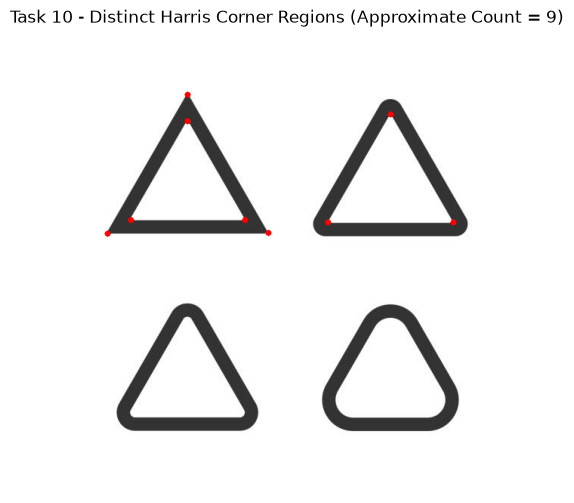

In [131]:
# ============================================================
# TASK 10 - IDENTIFY DISTINCT CORNER REGIONS
# ============================================================

print("\nTASK 10 - Draw Individual Corner Points")


# Use the NON-DILATED Harris response
# for better localisation.

threshold_value = (
    THRESHOLD_RATIO
    * harris_response.max()
)

corner_mask = (
    harris_response > threshold_value
).astype(np.uint8)


# Group neighbouring response pixels
number_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        corner_mask,
        connectivity=8
    )
)


result_points = img.copy()

corner_count = 0

for i in range(1, number_labels):

    x = int(round(centroids[i][0]))
    y = int(round(centroids[i][1]))

    cv2.circle(
        result_points,
        (x, y),
        radius=4,
        color=(0, 0, 255),
        thickness=-1
    )

    corner_count += 1


print(
    "Approximate number of distinct corner regions:",
    corner_count
)


result_points_rgb = cv2.cvtColor(
    result_points,
    cv2.COLOR_BGR2RGB
)

show_image(
    result_points_rgb,
    f"Task 10 - Distinct Harris Corner Regions "
    f"(Approximate Count = {corner_count})"
)

### Questions

- **Why might several points be detected around a single physical corner? Relate your answer to non-maximum suppression.**
  > A physical corner can produce a broad cluster of neighbouring pixels with large Harris responses. Thresholding marks every pixel in that cluster, so several points may appear around one corner. Non-maximum suppression keeps only a local maximum, or one representative maximum within a neighbourhood, and removes nearby weaker responses. Task 10 instead groups connected response pixels and draws one centroid per connected region, which is an approximate form of grouping rather than full non-maximum suppression.

## Final Comparison

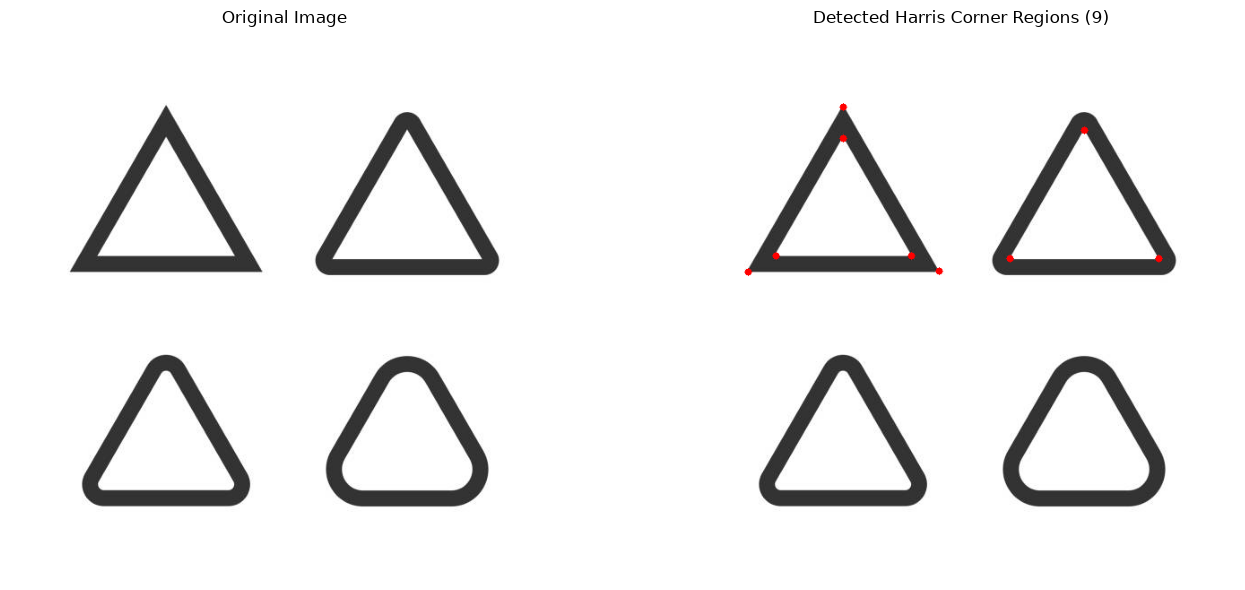


Tasks 1 to 10 completed successfully.


In [132]:
# ============================================================
# FINAL COMPARISON
# ============================================================

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_points_rgb)
plt.title(
    f"Detected Harris Corner Regions "
    f"({corner_count})"
)
plt.axis("off")

plt.tight_layout()
plt.show()


print("\n==========================================")
print("Tasks 1 to 10 completed successfully.")
print("==========================================")

**Additional images to try:**
- chess3.jpg
- corridor.jpg
- ImageD.jpg
- outdoor1.jpg
- outdoor3.jpg
- outdoor6.jpg
- Sample1.jpg
- Sample4.jpg
- Sample5.jpg
- Triangle.jpg
